# What each part does


``simulation.py`` handles neuronal dynamics and learning.

``experiment_utils.py`` contains the ``Experiment`` class. This handles experiment metadata, loading saved data, and coordinate transformations. It is an interface to the saved experiments.

``analysis_functions.py`` handles calculations such as correlations, \(R^2\), connectivity profiles, and motifs.

# Detailed info
* Connectivity convention: \(W_{ij}\) represents the connection from presynaptic neuron \(j\) to postsynaptic neuron \(i\), with recurrent input \(Wr\).
* Neuron assignment: The first int(N * pqif) neurons are QIF, and the remainder are LIF.
* Learning: independent_rls maintains a separate inverse correlation matrix for each postsynaptic neuron, whereas shared_rls uses one shared matrix.
* Sequence ordering: Neurons can be assigned random, ordered, or alternating sequence positions. When shared_sequence_order=False, targets are generated separately for each seed and pqif.
* Training: Loop 0 is untrained, loops 1 through nloop_train perform learning, and subsequent loops evaluate the trained network.
* FiI matching: LIF reset voltages are selected by comparing LIF and QIF firing-rate curves, with support for shifting negative target-derived current intervals.
* Analysis: Connectivity matrices can be reordered into sequence order, allowing connectivity profiles to be studied as functions of relative neuron distance.

# Seeding

For example, with master_seed=3002:

```bash
Random component	    Seed
Target	                    3002
External current	    103002
Network replicate 0	    3003
Network replicate 1	    3004
Network replicate 2	    3005
```

In [10]:
np.linspace(0.25, 0.9, 5),

(array([0.25  , 0.4125, 0.575 , 0.7375, 0.9   ]),)

Sequence ordering verified: 2 sequences across 500 neurons.


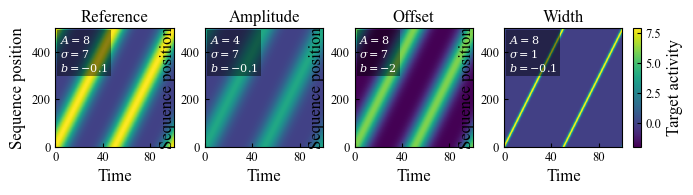

In [4]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.ticker import MaxNLocator

from config import Config
from targets import generate_sequences_target, order_sequence_target


# PARAMETERS

cfg = Config(N=500, dt=0.1, itmax=1000, number_sequences=2, target_dynamics="sequences")
TARGET_SEED = cfg.target_seed

REF_AMPLITUDE = 8.0
REF_OFFSET = -0.1
REF_SIGMA = 7.0

OTHER_AMPLITUDE = 4.0
OTHER_SIGMA = 1.0
OTHER_OFFSET = -2.0


# FIGURE SETTINGS

MM = 1 / 25.4
PANEL_MM = 30.0
LEFT_MM, RIGHT_MM = 13.0, 4.0
BOTTOM_MM, TOP_MM = 11.0, 7.0
GAP_X_MM, GAP_Y_MM = 8.0, 8.0

FONT_SIZE = 12
TICK_SIZE = 9
DPI = 100
CMAP = "viridis"

SHOW_COLORBAR = True
SHARED_COLOR_SCALE = True
SAVE_FIGURE = False
FIGURE_PATH = "sequence_target_comparison.svg"

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "font.size": FONT_SIZE,
    "axes.titlesize": FONT_SIZE,
    "axes.labelsize": FONT_SIZE,
    "axes.linewidth": 0.8,
    "xtick.labelsize": TICK_SIZE,
    "ytick.labelsize": TICK_SIZE,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "legend.fontsize": FONT_SIZE,
    "legend.frameon": False,
    "figure.dpi": DPI,
    "savefig.dpi": DPI,
    "savefig.bbox": "tight",
    "mathtext.fontset": "dejavuserif",
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


# GENERATE TARGETS

conditions = [
    ("Reference", REF_AMPLITUDE, REF_SIGMA, REF_OFFSET),
    ("Amplitude", OTHER_AMPLITUDE, REF_SIGMA, REF_OFFSET),
    ("Offset", REF_AMPLITUDE, REF_SIGMA, OTHER_OFFSET),
    ("Width", REF_AMPLITUDE, OTHER_SIGMA, REF_OFFSET),
]

targets = []
for name, amplitude, sigma, offset in conditions:
    rng = np.random.default_rng(TARGET_SEED)
    target, parameters, target_time = generate_sequences_target(
        amplitude=amplitude, sigma=sigma, offset=offset, cfg=cfg, rng=rng
    )
    targets.append(order_sequence_target(target, parameters))


# VALIDATE ORDERING

sequence_position = parameters["sequence_position"].to_numpy(dtype=int)
inverse_permutation = np.argsort(sequence_position)

assert np.array_equal(sequence_position[inverse_permutation], np.arange(cfg.N))
assert all(target.shape == (cfg.N, cfg.itmax) for target in targets)

print(f"Sequence ordering verified: {cfg.number_sequences} sequences across {cfg.N} neurons.")


# CREATE FIGURE

nrows, ncols = 1, len(conditions)
right_mm = RIGHT_MM + (12 if SHOW_COLORBAR else 0)
width_mm = LEFT_MM + ncols * PANEL_MM + (ncols - 1) * GAP_X_MM + right_mm
height_mm = BOTTOM_MM + nrows * PANEL_MM + (nrows - 1) * GAP_Y_MM + TOP_MM

fig, axes = plt.subplots(nrows, ncols, figsize=(width_mm * MM, height_mm * MM), squeeze=False)
axes = axes.ravel()

fig.subplots_adjust(
    left=LEFT_MM / width_mm, right=1 - right_mm / width_mm,
    bottom=BOTTOM_MM / height_mm, top=1 - TOP_MM / height_mm,
    wspace=GAP_X_MM / PANEL_MM, hspace=GAP_Y_MM / PANEL_MM
)

norm = None
if SHARED_COLOR_SCALE:
    norm = Normalize(vmin=min(x.min() for x in targets), vmax=max(x.max() for x in targets))


# PLOT

for ax, (name, amplitude, sigma, offset), target in zip(axes, conditions, targets):
    im = ax.imshow(
        target, origin="lower", aspect="auto", interpolation="nearest",
        extent=[0, cfg.dt * cfg.itmax, 0, cfg.N], cmap=CMAP, norm=norm
    )

    ax.set_box_aspect(1)
    ax.set_title(name, pad=5)
    ax.set_xlabel("Time")
    ax.set_ylabel("Sequence position")
    ax.xaxis.set_major_locator(MaxNLocator(nbins=3))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=3))

    ax.text(
        0.04, 0.96, rf"$A={amplitude:g}$" + "\n" + rf"$\sigma={sigma:g}$" + "\n" + rf"$b={offset:g}$",
        transform=ax.transAxes, ha="left", va="top", fontsize=8, color="white",
        bbox=dict(facecolor="black", alpha=0.45, edgecolor="none", pad=2)
    )


# COLORBAR

if SHOW_COLORBAR:
    pos = axes[-1].get_position()
    cax = fig.add_axes([pos.x1 + 0.015, pos.y0, 0.012, pos.height])
    fig.colorbar(im, cax=cax, label="Target activity")


# SAVE / DISPLAY

if SAVE_FIGURE:
    fig.savefig(FIGURE_PATH)

plt.show()


results/
    masterseed
        initialization_1
            1000_sequences
            1001_sequences
            ..
        initialization_2
            ..


# Initialize

Here we retrieve the experiment or experiments we are interested in. It becomes saved as an ``exp`` variable that contains everything we are interested in.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("plos.mplstyle")

from experiment_utils import Experiment
import analysis.analysis_functions as af

experiment_name = "1003_sequences"
exp = Experiment.find(experiment_name)

print(f"Initialized experiment: {exp.name}")
print(f"Location: {exp.directory}")

print("\nExperiment parameters:")
for key, value in exp.cfg.items():
    print(f"   {key}: {value}")

Initialized experiment: 1003_sequences
Location: C:\Users\snrambo\Projects\NEVR3901\HeterogenousRNN\HeterogeneousRNNs\learning\matrix_rls\results\1003_sequences

Experiment parameters:
   master_seed: 1003
   target_dynamics: sequences
   N: 500
   pqif_values: [0, 0.5, 1]
   configs: [{'vt': 0.0, 'vreset': -21.0}]
   p: 1
   gsyn: 0.5
   dt: 0.1
   itmax: 1000
   sigman: 1.0
   ts: 5.0
   itstim: 200
   current_amplitude: 16
   current_amplitude_by_pqif: None
   IEXT_LOW_FRAC: 0.0
   IEXT_HIGH_FRAC: 1.0
   alpha: 0.25
   nloop: 16
   nloop_train: 10
   cant_seed: 50
   ftrain: 1.0
   learning_algorithm: shared_rls
   allow_self_connections: True
   amp0: 4.0
   frequency_values: [1, 3, 5]
   number_sequences: 2
   sequence_amplitudes: [4.0, 16.0]
   sequence_sigmas: [7.0, 11.0]
   sequence_offsets: [0.0, 10.0]
   sequence_ordering: random
   shared_sequence_order: False
   parallelize_seed: 10
   parallelize_pqif: 1
   parallelize_target_conditions: 1
   save_inputs: True
   save_outp

How to use ``exp`` in analysis:

In [12]:
from experiment_utils import Experiment

exp = Experiment.find("1003_sequences")

print(exp.N)
print(exp.dt)
print(exp.itmax)
print(exp.nloop_train)
print(exp.pqif_values)
print(exp.shared_sequence_order)
print(exp.sequence_duration)
print(exp.save_activity_loops)
print(exp.cfg)
print(exp.iloop)

500
0.1
1000
10
[0.0, 0.5, 1.0]
False
50.0
[0, 11, 15]
{'master_seed': 1003, 'target_dynamics': 'sequences', 'N': 500, 'pqif_values': [0.0, 0.5, 1.0], 'configs': [{'vt': 0.0, 'vreset': -21.0}], 'p': 1, 'gsyn': 0.5, 'alpha': 0.25, 'dt': 0.1, 'itmax': 1000, 'sigman': 1.0, 'ts': 5.0, 'itstim': 200, 'current_amplitude': 24, 'current_amplitude_by_pqif': None, 'IEXT_LOW_FRAC': 0.0, 'IEXT_HIGH_FRAC': 1.0, 'nloop': 16, 'nloop_train': 10, 'cant_seed': 2, 'ftrain': 1.0, 'amp0': 4.0, 'frequency_values': [1, 3, 5], 'number_sequences': 2, 'sequence_amplitudes': [12.0], 'sequence_sigmas': [9.0], 'sequence_offsets': [0.0], 'sequence_ordering': 'random', 'shared_sequence_order': False, 'parallelize_seed': 1, 'parallelize_pqif': 3, 'parallelize_target_conditions': 1, 'save_inputs': True, 'save_outputs': True, 'save_nspikes': False, 'save_dw': False, 'notes': 'With the new changes from Martina', 'sim_name': '1003_sequences', 'derived': {'N2': 250, 'b': 0.2, 'sequence_duration': 50.0, 'save_activity_loop

AttributeError: Experiment has no attribute 'iloop'

Iterate over levels

In [3]:
for p in exp.iter_params("condition", "pqif", "seed", amplitude=12.0, pqif=0.5):
    print(p.condition.id, p.condition.parameters, p.pqif, p.seed)

0 {'amplitude': 12.0, 'sigma': 9.0, 'offset': 0.0} 0.5 0
0 {'amplitude': 12.0, 'sigma': 9.0, 'offset': 0.0} 0.5 1


Iterate over simulations and seeds

In [4]:
for p in exp.iter_params("sim", "seed", seed=[0, 1]):
    print(p.sim, p.seed)

1 0
1 1


Iterate over conditions filtered

In [4]:
for p in exp.iter_params("sim", "seed", seed=[0, 1]):
    print(p.sim, p.seed)

1 0
1 1


Get paths and load results

In [6]:
for p in exp.iter_params("condition", "sim", "pqif", "seed", pqif=0.5):
    path = exp.path("connectivity_matrix", condition=p.condition, sim=p.sim, pqif=p.pqif, seed=p.seed, iloop=exp.nloop_train + 1)
    W = np.load(path)
    print(p.condition.id, p.sim, p.pqif, p.seed, W.shape)

0 1 0.5 0 (500, 500)
0 1 0.5 1 (500, 500)


Load shared sequence:

In [ ]:
target, parameters = exp.load_target(condition=0, ordered=True)

Load independent sequences

In [10]:
target, parameters = exp.load_target(condition=0, sim=1, pqif=0.5, seed=0, ordered=True)

In [11]:
for p in exp.iter_params("condition", "sim", "pqif", "seed", amplitude=12.0):
    target, parameters = exp.load_target(condition=p.condition, sim=p.sim, pqif=p.pqif, seed=p.seed)
    print(p.condition.id, p.sim, p.pqif, p.seed, target.shape)

0 1 0.0 0 (500, 1000)
0 1 0.0 1 (500, 1000)
0 1 0.5 0 (500, 1000)
0 1 0.5 1 (500, 1000)
0 1 1.0 0 (500, 1000)
0 1 1.0 1 (500, 1000)


     neuron_index  sequence_position  peak_time  amplitude  sigma  offset  \
0               0                225       22.5       12.0    9.0     0.0   
1               1                330       33.0       12.0    9.0     0.0   
2               2                407       40.7       12.0    9.0     0.0   
3               3                211       21.1       12.0    9.0     0.0   
4               4                 51        5.1       12.0    9.0     0.0   
..            ...                ...        ...        ...    ...     ...   
495           495                401       40.1       12.0    9.0     0.0   
496           496                258       25.8       12.0    9.0     0.0   
497           497                300       30.0       12.0    9.0     0.0   
498           498                231       23.1       12.0    9.0     0.0   
499           499                299       29.9       12.0    9.0     0.0   

     sequence_duration  
0                 50.0  
1                 50.0  


Load network outputs

In [9]:
path = exp.path("outputs", condition=0, sim=1, pqif=0.5, seed=0, iloop=11)
with np.load(path) as data:
    outputs = data["outputs"].T

Now we don't need to specify paths:

In [2]:
condition_id=0
simulation_id = 1

condition_dir = exp.path("condition", condition=condition_id)
simulation_dir = exp.path("simulation", condition=condition_id, sim=simulation_id)

condition_dir

WindowsPath('C:/Users/snrambo/Projects/NEVR3901/HeterogenousRNN/HeterogeneousRNNs/learning/run_simulations/test/results/1003_sequences/condition_000')

And we can iterate over which layers we want and add filers:

In [3]:
for params in exp.iter_params("condition", "pqif", "seed"):
    print(params)

{'condition': 0, 'pqif': 0.0, 'seed': 0}
{'condition': 0, 'pqif': 0.0, 'seed': 1}
{'condition': 0, 'pqif': 0.5, 'seed': 0}
{'condition': 0, 'pqif': 0.5, 'seed': 1}
{'condition': 0, 'pqif': 1.0, 'seed': 0}
{'condition': 0, 'pqif': 1.0, 'seed': 1}


We can filter for specific parameters:

In [4]:
for params in exp.iter_params(
    "condition", "pqif", "seed",
    amplitude=12.0,
    pqif=0.5
    ):
    print(params)

{'condition': 0, 'pqif': 0.5, 'seed': 0}
{'condition': 0, 'pqif': 0.5, 'seed': 1}


Filter for more parameters (if non-existing, it just skips it):

In [5]:
for params in exp.iter_params("condition", "pqif", amplitude=[8.0, 12.0], pqif=[0.0, 0.5]):
    print(params)

{'condition': 0, 'pqif': 0.0}
{'condition': 0, 'pqif': 0.5}


In [6]:
# Vary one parameter while keeping the others fixed

from experiment_utils import Experiment



# Vary amplitude
for condition in exp.conditions(sigma=8.0, offset=0.0):
    print(
        f"Condition {condition.id}: "
        f"amplitude={condition.amplitude}, "
        f"sigma={condition.sigma}, "
        f"offset={condition.offset}"
    )

# Vary sigma
for condition in exp.conditions(amplitude=8.0, offset=0.0):
    print(condition.sigma)


# Vary offset
for condition in exp.conditions(amplitude=8.0, sigma=8.0):
    print(condition.offset)

Condition 0: amplitude=8.0, sigma=8.0, offset=0.0
Condition 4: amplitude=12.0, sigma=8.0, offset=0.0
8.0
9.0
0.0
5.0


How to reorder according to sequence position:

 sequence_position  neuron_index neuron_model  peak_time
                 0           415          LIF        0.0
                 1           100          QIF        0.1
                 2           317          LIF        0.2
                 3           479          LIF        0.3
                 4            66          QIF        0.4
                 5           452          LIF        0.5
                 6           127          QIF        0.6
                 7           342          LIF        0.7
                 8           266          LIF        0.8
                 9           380          LIF        0.9
                10            67          QIF        1.0
                11           163          QIF        1.1
                12           210          QIF        1.2
                13           258          LIF        1.3
                14           379          LIF        1.4
                15           126          QIF        1.5
                16           29

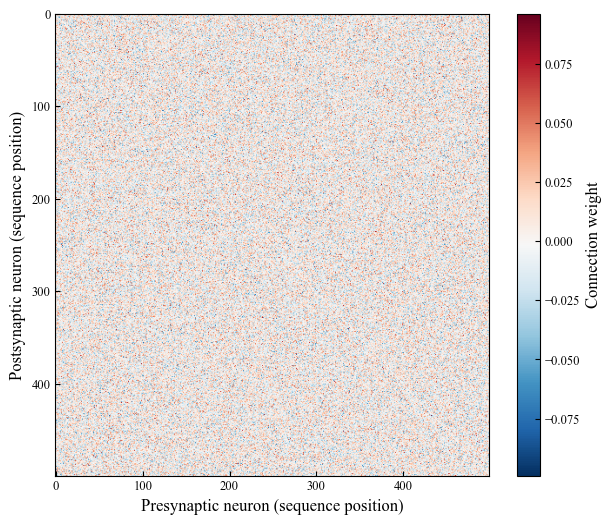

In [6]:
# condition_id = 0
# simulation_id = 1
# pqif = 0.5
# seed = 0
# iloop = 0

# condition_dir = exp.directory / f"condition_{condition_id:03d}"
# simulation_dir = condition_dir / f"simulation_{simulation_id}"

# parameters = pd.read_csv(condition_dir / "target_parameters.csv")
# assignment = pd.read_csv(simulation_dir / f"neuron_assignment_pqif_{pqif}.csv")
# sequence = parameters.merge(assignment, on="neuron_index").sort_values("sequence_position")

# order = sequence["neuron_index"].to_numpy(dtype=int)
# print(sequence[["sequence_position", "neuron_index", "neuron_model", "peak_time"]].to_string(index=False))
# print("Neuron types in sequence order:", sequence["neuron_model"].tolist())

# w_path = simulation_dir / "connectivity_matrix" / f"simulation_{simulation_id}_connectivity_pqif_{pqif}_iloop_{iloop}_seed_{seed}.npy"
# w = np.load(w_path)
# w_ordered = w[np.ix_(order, order)]

# plt.figure(figsize=(7, 6))
# plt.imshow(w_ordered, aspect="auto", cmap="RdBu_r")
# plt.xlabel("Presynaptic neuron (sequence position)")
# plt.ylabel("Postsynaptic neuron (sequence position)")
# plt.colorbar(label="Connection weight")
# plt.show()



# If the sequence order is not shared across seeds

condition_id = 0
simulation_id = 1
pqif = 0.5
seed = 0
iloop = 0

condition_dir = exp.directory / f"condition_{condition_id:03d}"
simulation_dir = condition_dir / f"simulation_{simulation_id}"

# Load seed-specific sequence parameters
parameters = pd.read_csv(simulation_dir/ "sequence_assignments"/ f"sequence_sim_{simulation_id}_pqif_{pqif}_seed_{seed}.csv")

# Load QIF/LIF neuron assignment
assignment = pd.read_csv(simulation_dir / f"neuron_assignment_pqif_{pqif}.csv")

# Merge and sort neurons by their actual sequence position
sequence = (parameters.merge(assignment, on="neuron_index").sort_values("sequence_position"))

order = sequence["neuron_index"].to_numpy(dtype=int)

print(sequence[["sequence_position", "neuron_index", "neuron_model", "peak_time"]].to_string(index=False))

print("Neuron types in sequence order:", sequence["neuron_model"].tolist())

# Load connectivity matrix
w_path = (simulation_dir/ "connectivity_matrix"/ f"simulation_{simulation_id}_connectivity_pqif_{pqif}_iloop_{iloop}_seed_{seed}.npy")

w = np.load(w_path)

# Reorder both postsynaptic and presynaptic neurons
w_ordered = w[np.ix_(order, order)]

plt.figure(figsize=(7, 6))
plt.imshow(w_ordered, aspect="auto", cmap="RdBu_r")
plt.xlabel("Presynaptic neuron (sequence position)")
plt.ylabel("Postsynaptic neuron (sequence position)")
plt.colorbar(label="Connection weight")
plt.show()

**Shared sequence order or not**
Across seeds, neurons can share sequence order or not (determined by the parameter ``shared_sequence_order`` in config). This defaults to ``True``, but if set to ```False``, any seed have its own randomized order.

**Shared**

![alt text](tutorial_im/shared_order.png "Title")


**Not shared**

![alt text](tutorial_im/not_shared_order.png "Title")

In [3]:
# Loop through all combinations

for p in exp.iter("condition", "sim", "pqif", "seed"):
    W = exp.load_connectivity(
        condition=p.condition,
        sim=p.sim,
        pqif=p.pqif,
        seed=p.seed,
    )

    print(
        p.condition.amplitude,
        p.sim,
        p.pqif,
        p.seed,
        W.shape,
    )




8.0 1 0.0 0 (500, 500)
8.0 1 0.0 1 (500, 500)
8.0 1 0.5 0 (500, 500)
8.0 1 0.5 1 (500, 500)
8.0 1 1.0 0 (500, 500)
8.0 1 1.0 1 (500, 500)
8.0 1 0.0 0 (500, 500)
8.0 1 0.0 1 (500, 500)
8.0 1 0.5 0 (500, 500)
8.0 1 0.5 1 (500, 500)
8.0 1 1.0 0 (500, 500)
8.0 1 1.0 1 (500, 500)
8.0 1 0.0 0 (500, 500)
8.0 1 0.0 1 (500, 500)
8.0 1 0.5 0 (500, 500)
8.0 1 0.5 1 (500, 500)
8.0 1 1.0 0 (500, 500)
8.0 1 1.0 1 (500, 500)
8.0 1 0.0 0 (500, 500)
8.0 1 0.0 1 (500, 500)
8.0 1 0.5 0 (500, 500)
8.0 1 0.5 1 (500, 500)
8.0 1 1.0 0 (500, 500)
8.0 1 1.0 1 (500, 500)
12.0 1 0.0 0 (500, 500)
12.0 1 0.0 1 (500, 500)
12.0 1 0.5 0 (500, 500)
12.0 1 0.5 1 (500, 500)
12.0 1 1.0 0 (500, 500)
12.0 1 1.0 1 (500, 500)
12.0 1 0.0 0 (500, 500)
12.0 1 0.0 1 (500, 500)
12.0 1 0.5 0 (500, 500)
12.0 1 0.5 1 (500, 500)
12.0 1 1.0 0 (500, 500)
12.0 1 1.0 1 (500, 500)
12.0 1 0.0 0 (500, 500)
12.0 1 0.0 1 (500, 500)
12.0 1 0.5 0 (500, 500)
12.0 1 0.5 1 (500, 500)
12.0 1 1.0 0 (500, 500)
12.0 1 1.0 1 (500, 500)
12.0 1 0.0 0 (50

In [4]:
# Average connectivity over seeds

import numpy as np
import pandas as pd

results = []

for p in exp.iter(
    "condition", "sim", "pqif",
    sigma=8.0,
    offset=0.0,
):
    matrices = [
        exp.load_connectivity(
            condition=p.condition,
            sim=p.sim,
            pqif=p.pqif,
            seed=seed,
        )
        for seed in exp.seeds
    ]

    avg_W = np.mean(matrices, axis=0)

    results.append({
        "condition": p.condition.id,
        "amplitude": p.condition.amplitude,
        "sigma": p.condition.sigma,
        "offset": p.condition.offset,
        "sim": p.sim,
        "pqif": p.pqif,
        "mean_weight": np.mean(avg_W),
        "std_weight": np.std(avg_W, ddof=1),
    })

avgDF = pd.DataFrame(results)

In [5]:
# Separate plot for each condition

for condition in exp.conditions(sigma=8.0, offset=0.0):

    print(f"Amplitude: {condition.amplitude}")

    for p in exp.iter(
        "sim", "pqif",
        condition=condition,
    ):
        matrices = [
            exp.load_connectivity(
                condition=condition,
                sim=p.sim,
                pqif=p.pqif,
                seed=seed,
            )
            for seed in exp.seeds
        ]

        avg_W = np.mean(matrices, axis=0)

        # Analyze or plot avg_W

Amplitude: 8.0
Amplitude: 12.0


In [6]:
# Load target activity and target data

# Can use same for input, output, spikes

for p in exp.iter(
    "condition", "sim", "pqif", "seed",
    amplitude=8.0,
    sigma=8.0,
    offset=0.0,
):
    outputs = exp.load_activity(
        "outputs",
        condition=p.condition,
        sim=p.sim,
        pqif=p.pqif,
        seed=p.seed,
        iloop=11,
    )

    target = np.load(
        exp.path("target", condition=p.condition)
    )

    # Both arrays have shape (N, itmax)
    # Both can now be passed to correlation_summary() in analysis_functions.py
    

A=8.0, vreset=-15.50
A=12.0, vreset=-16.00


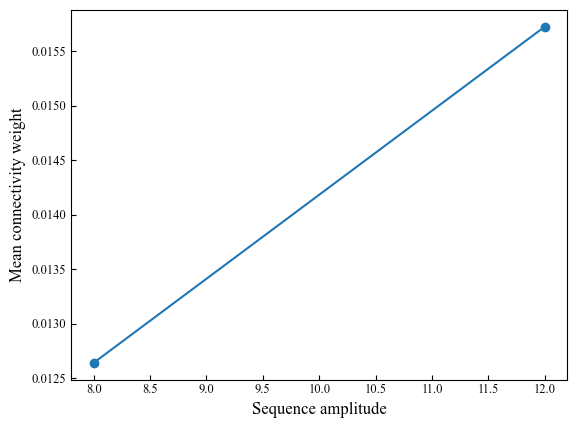

In [7]:
# Plot average connectivity weight against amplitude, keeping sigma and offset fixed, and including vreset in the info

import numpy as np
import matplotlib.pyplot as plt

amplitudes = []
mean_weights = []
vresets = []

for condition in exp.conditions(sigma=8.0, offset=0.0):

    vreset = exp.get_vreset(condition)

    matrices = [
        exp.load_connectivity(
            condition=condition,
            sim=1,
            pqif=0.5,
            seed=seed,
        )
        for seed in exp.seeds
    ]

    avg_W = np.mean(matrices, axis=0)

    amplitudes.append(condition.amplitude)
    mean_weights.append(np.mean(avg_W))
    vresets.append(vreset)

    print(f"A={condition.amplitude}, vreset={vreset:.2f}")

plt.plot(amplitudes, mean_weights, "o-")
plt.xlabel("Sequence amplitude")
plt.ylabel("Mean connectivity weight")
plt.show()

# Deciding on parameters

In [ ]:
# Put here the code for visualizing targets

In [ ]:
# How many combinations from a given range of parameters
from itertools import product

sequence_amplitudes = (np.linspace(2, 16, 3)).tolist()
sequence_sigmas = (np.linspace(7, 11, 3)).tolist()
sequence_offsets = (np.linspace(-10, 2, 3)).tolist()

sequence_parameter_combinations = list(product(sequence_amplitudes, sequence_sigmas, sequence_offsets,))  # Cartesian product of the sequence parameters

print(len(sequence_parameter_combinations))

27


# Debugging

## File not found error

After initializing ``exp``, if the file for some reason is not found when you iterate using ``iter_params``, try:

In [ ]:
from pathlib import Path

path = exp.path("inputs", condition=0, sim=1, pqif=1, seed=38, iloop=11)


print("Constructed path:", path)
print("Absolute path:", path.resolve())
print("File exists:", path.is_file())
print("Parent exists:", path.parent.is_dir())

print("\nMatching files:")
for file in path.parent.glob("*seed_38*"):
    print(repr(file.name))


for name in ("inputs", "outputs"):
    path = exp.path(name, condition=0, sim=1, pqif=1, seed=38, iloop=11)
    print(name, path.is_file(), path)

## Inspect

In [2]:
import inspect

print(inspect.getsource(Experiment.load_network))
print(hasattr(Experiment, "load_npz_with_retry"))

    def load_target(
        self, condition, sim=None, pqif=None, seed=None,
        reorder=True, include_itstim=False
    ):
        """Load target activity, shaped (neurons, time)."""

        target = np.load(self.path("target", condition=condition))
        parameters = pd.read_csv(
            self.path("target_parameters", condition=condition)
        )

        if self.target_dynamics == "sequences" and not self.shared_sequence_order:
            if sim is None or pqif is None or seed is None:
                raise ValueError("Seed-specific targets require sim, pqif, and seed")

            canonical_order = np.argsort(
                parameters["sequence_position"].to_numpy(dtype=int)
            )

            parameters = pd.read_csv(
                self.path(
                    "sequence_assignment", condition=condition,
                    sim=sim, pqif=pqif, seed=seed
                )
            )

            positions = parameters["sequence_position"].to_numpy(dty